Calculate where recorded recall sequences end. Compare stopping distributions with conditional stopping probabilities, mark the recording boundary and save the figure.

## Settings


In [1]:
#| code-summary: "1 — Set the parameters for this run"

# Working directory (None discovers the enclosing Git project).
project_root = None


# Response files
data_path = None  # A supplied single path takes precedence over data_paths.
data_paths = [
    "data/Dupertuys2026.h5",
    "data/simulations/Dupertuys2026_CMR_demo_best_of_3.h5",
    "data/simulations/Dupertuys2026_eCMR_source_only_demo_best_of_3.h5",
    "data/simulations/Dupertuys2026_eCMR_broad_demo_best_of_3.h5",
]
data_labels = ["Observed", "CMR", "Source-only eCMR", "Broader eCMR"]

# Saved results
output_dir = "results/termination_probability"


# Analysis and uncertainty settings
confidence_level = 0.95
plot_seed = 0  # NumPy seed for bootstrap displays.

max_subjects = 0
figure_dir = None
figure_str = "termination"  # Empty displays the figure without saving it.


# Condition selection
trial_query = None  # When supplied, use this one selection instead of trial_queries.
trial_queries = [
    "jnp.equal(data['list_type'], 1)",
    "jnp.equal(data['list_type'], 2)",
    "jnp.equal(data['list_type'], 3)",
]
labels = ["Mixed", "Pure emotional", "Pure neutral"]
selection_label = "Selected lists"
contrast_name = None  # Legend title for the selected comparisons.
complete_lists_only = True


# Figure appearance
color_cycle = None
ylim = None
yticks = None


# Stopping summaries
mode = ["simple", "conditional"]  # A single mode string is also accepted.


In [2]:
#| code-summary: "2 — Prepare the Colab environment"

import sys

if "google.colab" in sys.modules:
    import subprocess

    revision = "main"
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--upgrade",
            f"jaxcmr[colab] @ git+https://github.com/githubpsyche/jaxcmr.git@{revision}",
        ]
    )
    from jaxcmr.colab import fetch_inputs

    fetch_inputs(
        ([data_path] if data_path is not None else data_paths), revision=revision, base_dir=project_root
    )


In [3]:
#| code-summary: "3 — Import packages"

import sys
from pathlib import Path

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from jaxcmr.analyses.termination_probability import plot_termination_probability
from jaxcmr.helpers import find_project_root, resolve_project_path, generate_trial_mask, load_data, save_figure


## Select the observations


In [4]:
#| code-summary: "4 — Resolve input paths, conditions and output settings"

if project_root is not None:
    root_path = resolve_project_path(project_root, Path.cwd())
elif "google.colab" in sys.modules:
    root_path = Path.cwd()
else:
    try:
        root_path = Path(find_project_root())
    except FileNotFoundError:
        root_path = Path.cwd()
print("Project directory:", root_path)

np.random.seed(plot_seed)
output_dir = resolve_project_path(output_dir, root_path)
figure_dir = resolve_project_path(figure_dir, root_path) if figure_dir is not None else output_dir

queries = trial_queries if trial_query is None else [trial_query]
condition_labels = labels if trial_query is None else [selection_label]
input_paths = [data_path] if data_path is not None else data_paths
input_paths = [resolve_project_path(path, root_path) for path in input_paths]
input_labels = [selection_label] if data_path is not None else data_labels
if len(queries) != len(condition_labels) or len(input_paths) != len(input_labels):
    raise ValueError("Supply a label for each input and each condition query.")


In [5]:
#| code-summary: "5 — Load the supplied response datasets"

datasets = [load_data(str(path), max_subjects=max_subjects) for path in input_paths]


In [6]:
#| code-summary: "6 — Select observations and report participant counts"

masks_by_dataset = []
for dataset, dataset_label in zip(datasets, input_labels):
    condition_masks = [generate_trial_mask(dataset, query) for query in queries]
    if complete_lists_only:
        condition_masks = [
            condition_mask & jnp.all(dataset["pres_itemnos"] > 0, axis=1)
            for condition_mask in condition_masks
        ]
    masks_by_dataset.append(condition_masks)
    for condition_label, condition_mask in zip(condition_labels, condition_masks):
        participant_ids = np.unique(
            np.asarray(dataset["subject"]).ravel()[np.asarray(condition_mask)]
        )
        print(
            f"{dataset_label} / {condition_label}: {int(condition_mask.sum())} lists, {len(participant_ids)} participants"
        )
        if not len(participant_ids):
            raise ValueError(
                "The selected input and condition contain no eligible lists."
            )
data, trial_masks = datasets[0], masks_by_dataset[0]


Observed / Mixed: 246 lists, 123 participants
Observed / Pure emotional: 122 lists, 122 participants
Observed / Pure neutral: 123 lists, 123 participants
CMR / Mixed: 2460 lists, 123 participants
CMR / Pure emotional: 1220 lists, 122 participants
CMR / Pure neutral: 1230 lists, 123 participants
Source-only eCMR / Mixed: 2460 lists, 123 participants
Source-only eCMR / Pure emotional: 1220 lists, 122 participants
Source-only eCMR / Pure neutral: 1230 lists, 123 participants
Broader eCMR / Mixed: 2460 lists, 123 participants
Broader eCMR / Pure emotional: 1220 lists, 122 participants
Broader eCMR / Pure neutral: 1230 lists, 123 participants


## Identify the recording boundary


In [7]:
#| code-summary: "7 — Prepare the condition and dataset comparison panels"

panels = []
if data_path is not None:
    panels.append(
        {
            "datasets": [data] * len(queries),
            "trial_masks": trial_masks,
            "labels": condition_labels,
            "title": selection_label,
        }
    )
else:
    for condition_index, condition_label in enumerate(condition_labels):
        panels.append(
            {
                "datasets": datasets,
                "trial_masks": [masks[condition_index] for masks in masks_by_dataset],
                "labels": input_labels,
                "title": condition_label,
            }
        )

modes = [mode] if isinstance(mode, str) else mode
mode_panels = []
for panel in panels:
    for display_mode in modes:
        mode_panels.append({**panel, "mode": display_mode})
panels = mode_panels


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/stats/_resampling.py:156: RuntimeWarning: invalid value encountered in divide
  a_hat = 1/6 * sum(nums) / sum(dens)**(3/2)
/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/stats/_resampling.py:156: RuntimeWarning: invalid value encountered in divide
  a_hat = 1/6 * sum(nums) / sum(dens)**(3/2)
/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/stats/_resampling.py:156: RuntimeWarning: invalid value encountered in divide
  a_hat = 1/6 * sum(nums) / sum(dens)**(3/2)
/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)
/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/stats/_resampling.py:156: RuntimeWarning: invalid value encountered in divide
  a_hat = 1/6 * sum(nums) / sum(dens)**(3/2)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/stats/_resampling.py:156: RuntimeWarning: invalid value encountered in divide
  a_hat = 1/6 * sum(nums) / sum(dens)**(3/2)
/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/stats/_resampling.py:156: RuntimeWarning: invalid value encountered in divide
  a_hat = 1/6 * sum(nums) / sum(dens)**(3/2)
/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


... (13 outputs left out)

/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/stats/_resampling.py:156: RuntimeWarning: invalid value encountered in divide
  a_hat = 1/6 * sum(nums) / sum(dens)**(3/2)
/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/stats/_resampling.py:156: RuntimeWarning: invalid value encountered in divide
  a_hat = 1/6 * sum(nums) / sum(dens)**(3/2)
/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/stats/_resampling.py:156: RuntimeWarning: invalid value encountered in divide
  a_hat = 1/6 * sum(nums) / sum(dens)**(3/2)
/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/stats/_resampling.py:156: RuntimeWarning: invalid value encountered in divide
  a_hat = 1/6 * sum(nums) / sum(dens)**(3/2)
/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


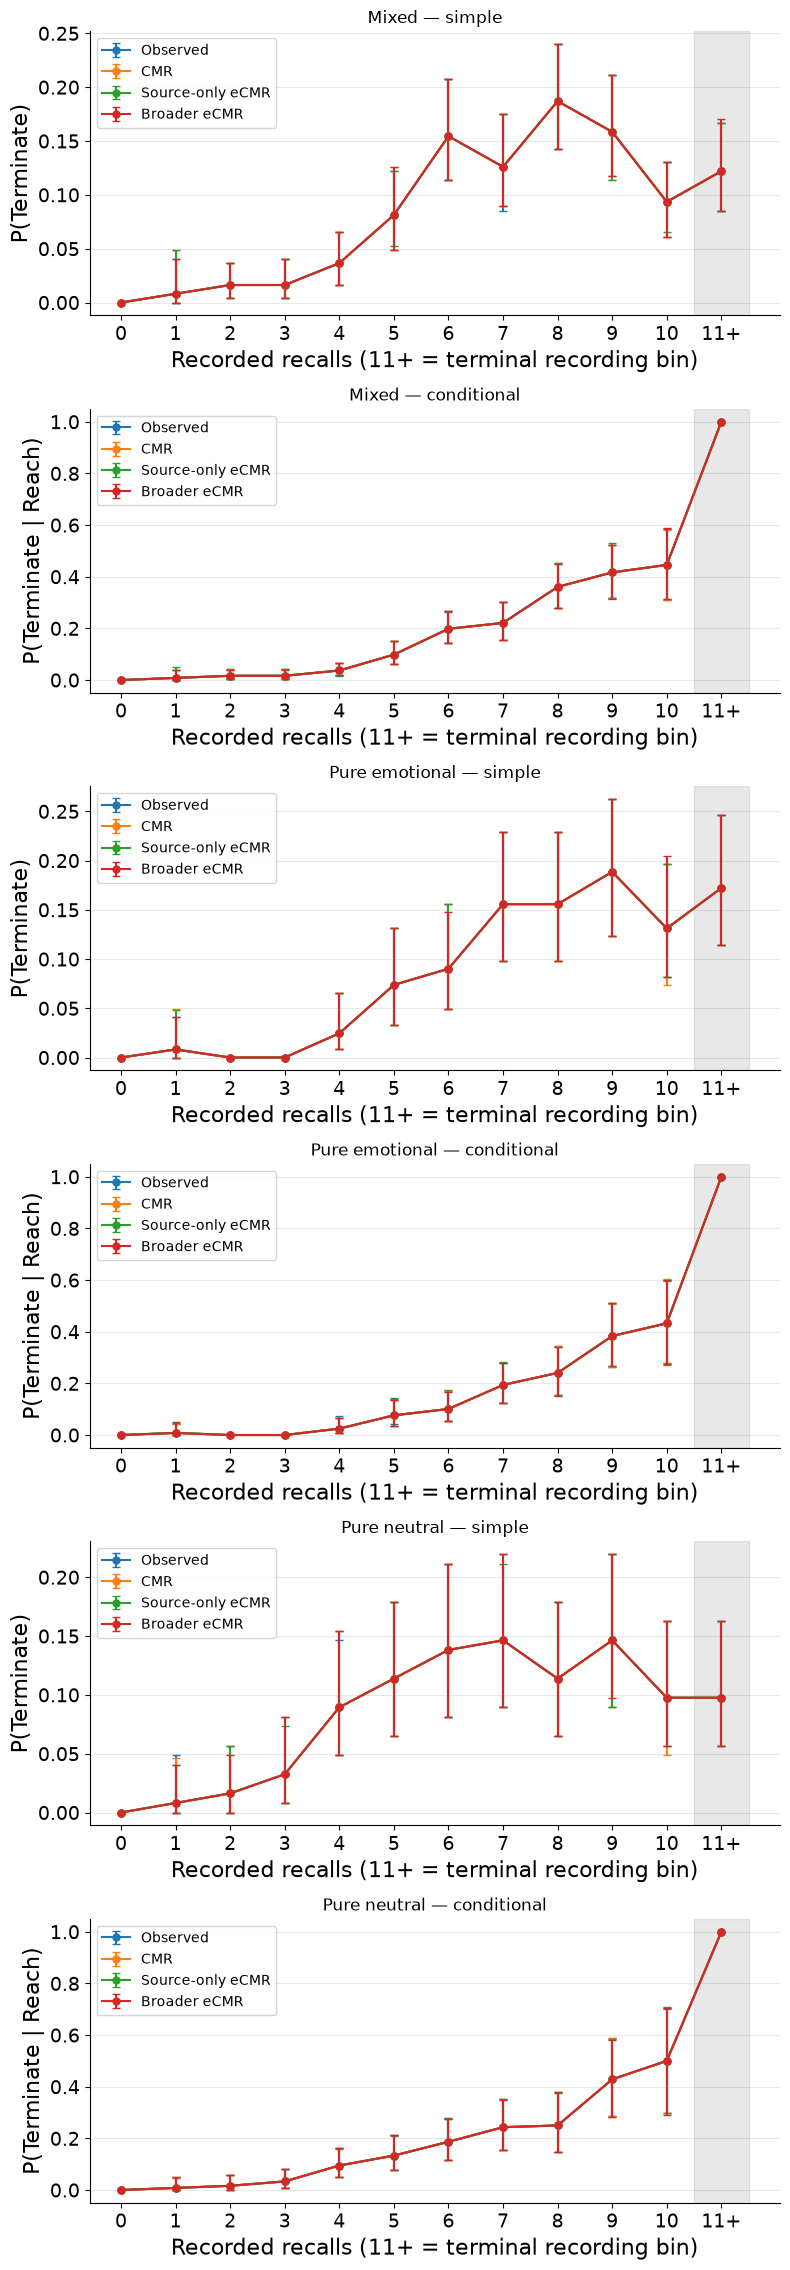

In [8]:
#| code-summary: "8 — Calculate, plot and save the selected comparison"

fig, axes = plt.subplots(len(panels), 1, figsize=(8, 3.8 * len(panels)), squeeze=False)
for ax, panel in zip(axes.ravel(), panels):
    panel_data = panel["datasets"]
    panel_masks = panel["trial_masks"]
    curve_labels = panel["labels"]
    title = panel["title"]
    display_mode = panel["mode"]
    plot_termination_probability(
        panel_data,
        panel_masks,
        mode=display_mode,
        labels=curve_labels,
        contrast_name=contrast_name,
        color_cycle=color_cycle,
        confidence_level=confidence_level,
        axis=ax,
    )
    title += f" — {display_mode}"
    widths = {dataset["recalls"].shape[1] for dataset in panel_data}
    if len(widths) != 1:
        raise ValueError(
            "Use matching recording capacities for overlaid terminal bins."
        )
    capacity = widths.pop()
    ax.set_xticks(
        np.arange(1, capacity + 1),
        [str(i) for i in range(capacity - 1)] + [f"{capacity - 1}+"],
    )
    ax.set_xlabel(f"Recorded recalls ({capacity - 1}+ = terminal recording bin)")
    ax.axvspan(capacity - 0.5, capacity + 0.5, color="grey", alpha=0.18)
    ax.set_title(title)

    if ax.get_legend_handles_labels()[1]:
        ax.legend(title=contrast_name)
    if ylim is not None:
        ax.set_ylim(ylim)
    if yticks is not None:
        ax.set_yticks(yticks)
save_figure(str(figure_dir), figure_str)
